# Recognize food with ResNet50 (Food-101), fixed for Kaggle

**Before running:** attach the Food-101 dataset (right sidebar → *Add Input*), and turn on a GPU (*Settings → Accelerator → GPU*).
Internet is only needed for the optional "test on images from the web" cells.

### **Imports**

In [1]:
import os, random, json, shutil
from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import tensorflow as tf
import tensorflow.keras.backend as K
from tensorflow.keras import regularizers
from tensorflow.keras.applications.resnet50 import ResNet50
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import ModelCheckpoint, CSVLogger
from tensorflow.keras.optimizers import SGD

In [2]:
# Check versions and that the GPU is enabled
print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


### **Locate the Food-101 dataset**
The dataset is already attached under `/kaggle/input`, so nothing is downloaded. This finds the real `images` folder automatically
(skipping the `__MACOSX` junk folder) and sets every path from it. `/kaggle/input` is read-only, so all outputs go to `/kaggle/working`.

In [3]:
BASE = None
for root, dirs, files in os.walk("/kaggle/input"):
    dirs[:] = [d for d in dirs if d != "__MACOSX"]       # ignore macOS metadata folders
    if os.path.basename(root) == "images" and os.path.isdir(os.path.join(os.path.dirname(root), "meta")):
        BASE = os.path.dirname(root)
        break

assert BASE is not None, "Food-101 not found. Attach it with 'Add Input' in the right sidebar."
WORK = "/kaggle/working"
data_dir = os.path.join(BASE, "images")
meta_dir = os.path.join(BASE, "meta")
os.chdir(WORK)

print("BASE     :", BASE)
print("images   :", data_dir)
print("meta     :", meta_dir)
print("classes  :", len([f for f in os.listdir(data_dir) if not f.startswith(".")]))   # should be 101

BASE     : /kaggle/input/datasets/dansbecker/food-101/food-101/food-101
images   : /kaggle/input/datasets/dansbecker/food-101/food-101/food-101/images
meta     : /kaggle/input/datasets/dansbecker/food-101/food-101/food-101/meta
classes  : 101


### **Understand dataset structure and files**

In [4]:
!ls "{BASE}"

images	license_agreement.txt  meta  README.txt


In [5]:
os.listdir(meta_dir)

['test.txt',
 'train.json',
 'labels.txt',
 'test.json',
 'train.txt',
 'classes.txt']

In [6]:
!head "{meta_dir}/train.txt"

apple_pie/1005649
apple_pie/1014775
apple_pie/1026328
apple_pie/1028787
apple_pie/1043283
apple_pie/1050519
apple_pie/1057749
apple_pie/1057810
apple_pie/1072416
apple_pie/1074856


In [7]:
!head "{meta_dir}/classes.txt"

apple_pie
baby_back_ribs
baklava
beef_carpaccio
beef_tartare
beet_salad
beignets
bibimbap
bread_pudding
breakfast_burrito


### **Visualize random image from each of the 101 classes**

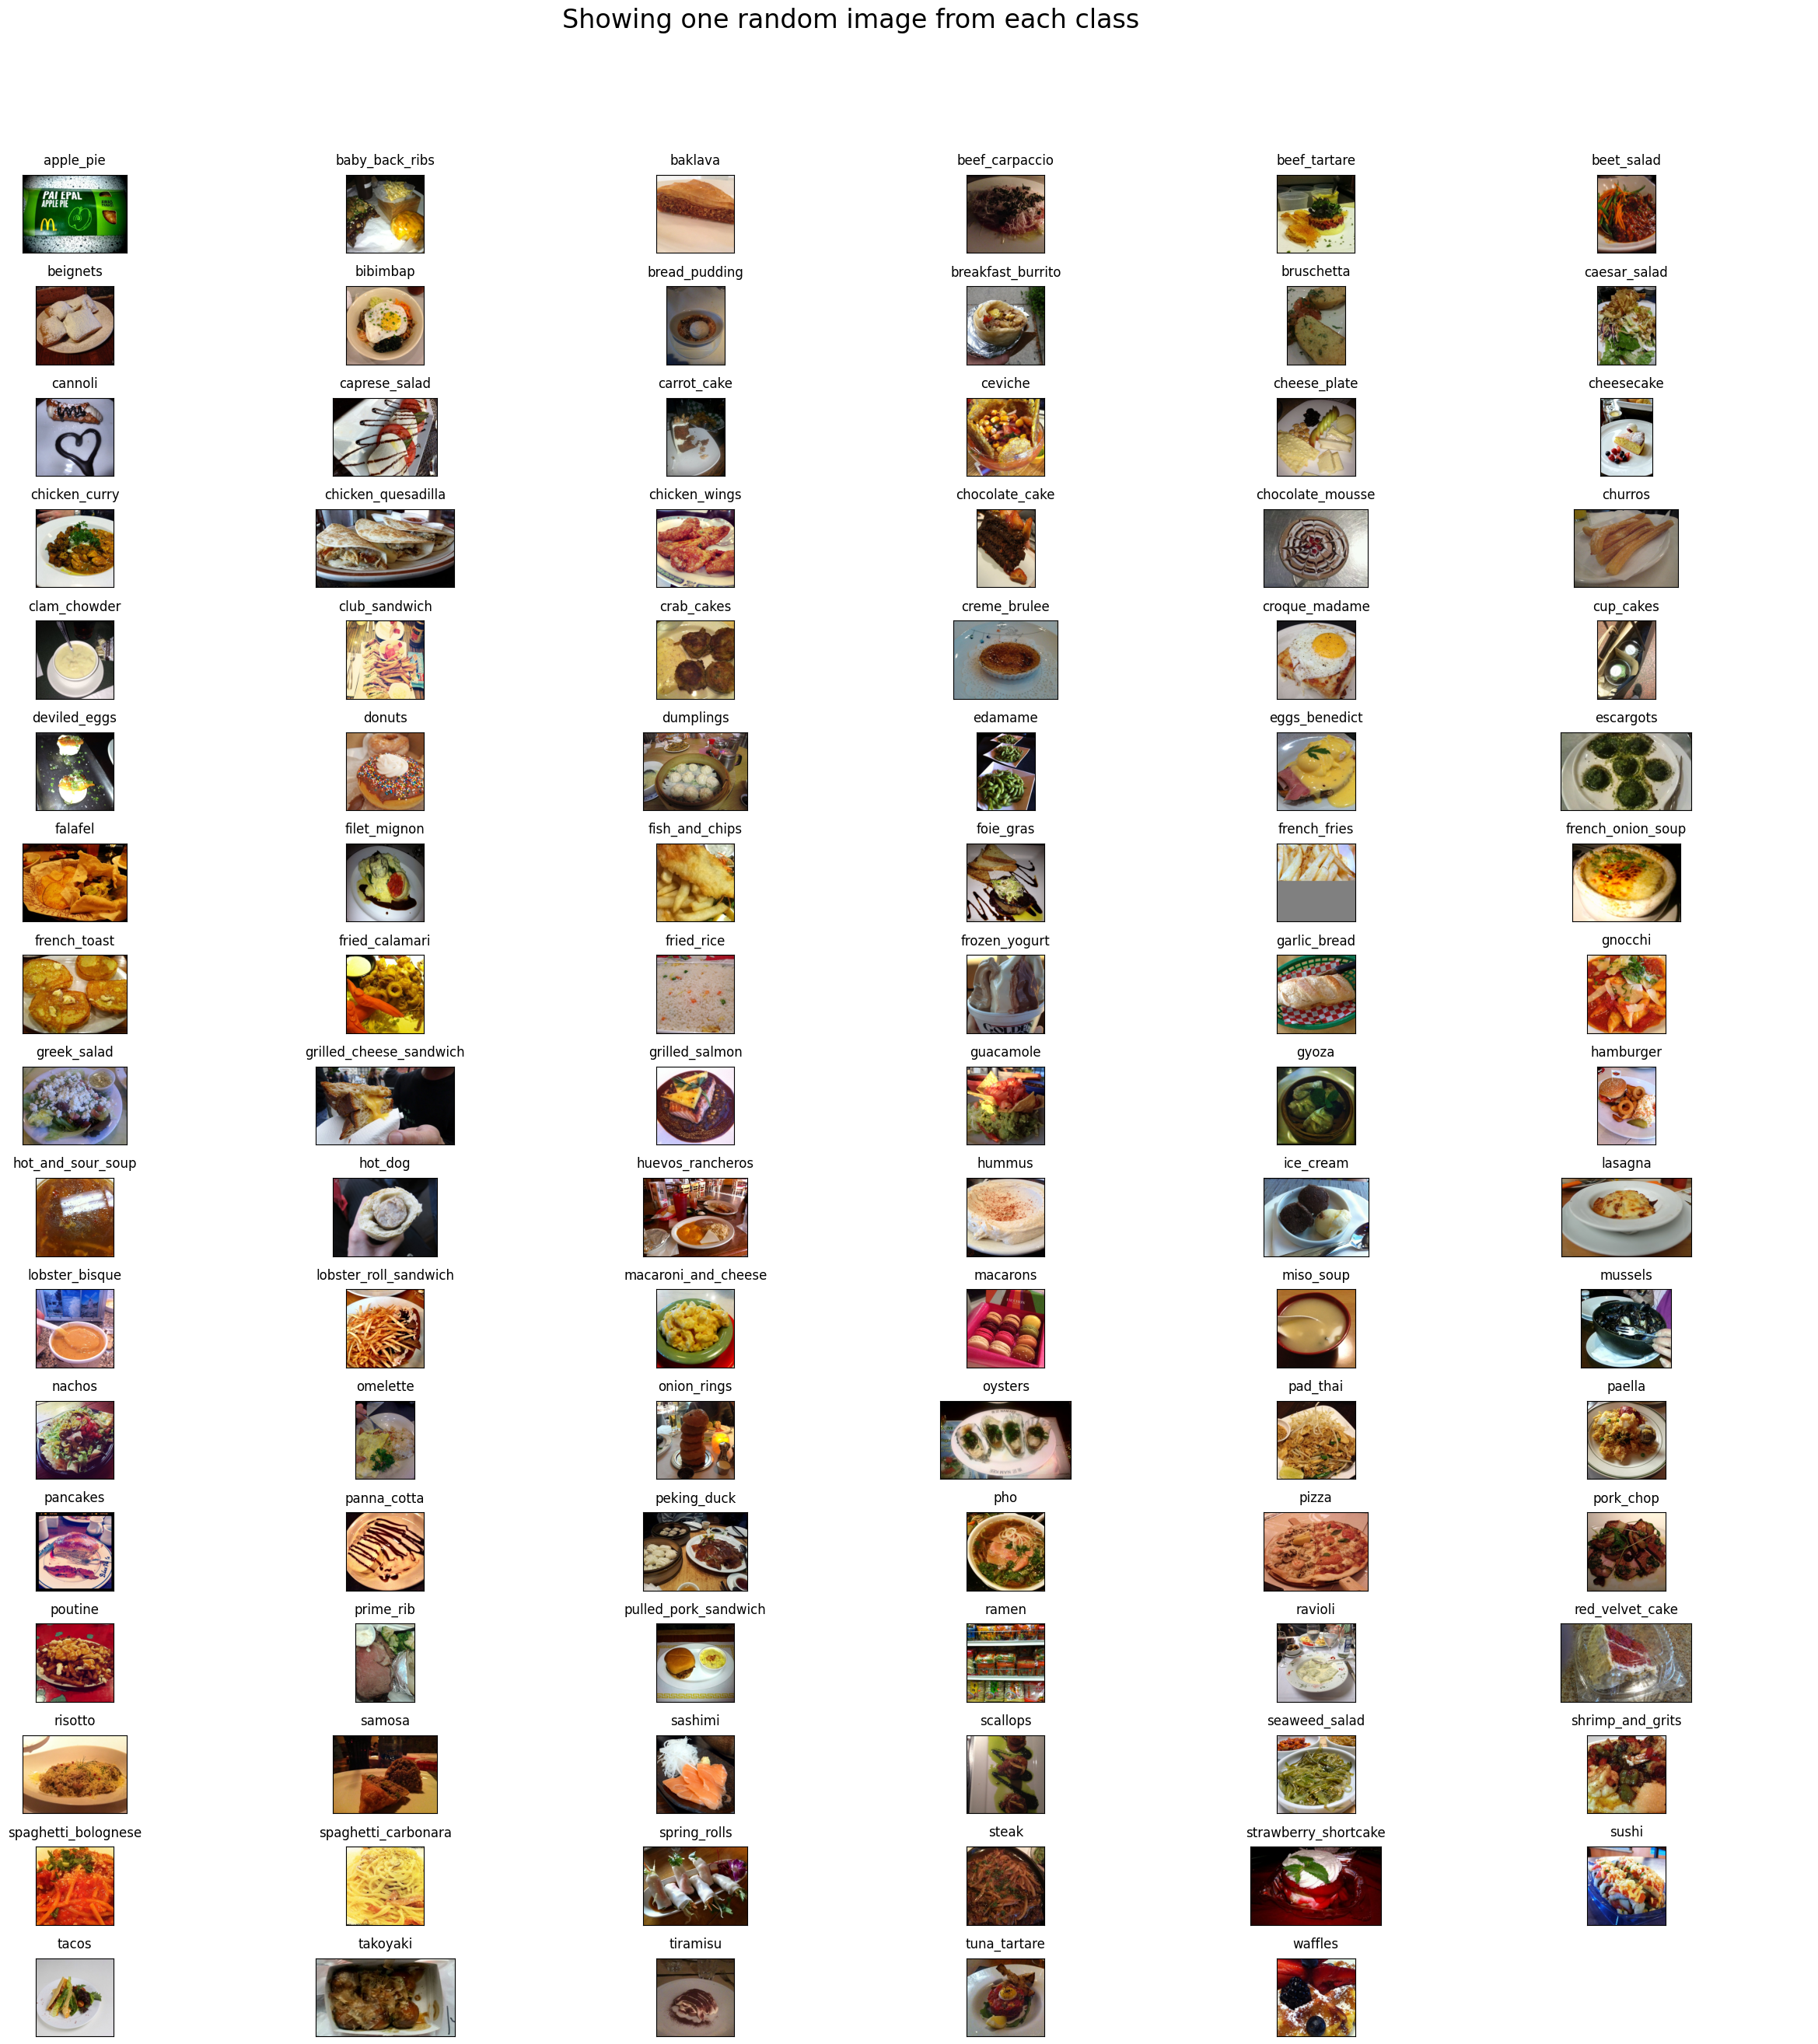

In [8]:
rows, cols = 17, 6
fig, ax = plt.subplots(rows, cols, figsize=(25, 25))
fig.suptitle("Showing one random image from each class", y=1.05, fontsize=24)

foods_sorted = sorted(f for f in os.listdir(data_dir) if not f.startswith("."))   # skips .DS_Store etc.

food_id = 0
for i in range(rows):
    for j in range(cols):
        if food_id >= len(foods_sorted):
            ax[i][j].axis("off")          # 17*6 = 102 slots for 101 classes
            continue
        food_selected = foods_sorted[food_id]
        food_id += 1
        images = [f for f in os.listdir(os.path.join(data_dir, food_selected)) if not f.startswith(".")]
        img = plt.imread(os.path.join(data_dir, food_selected, np.random.choice(images)))
        ax[i][j].imshow(img)
        ax[i][j].set_title(food_selected, pad=10)

plt.setp(ax, xticks=[], yticks=[])
plt.tight_layout()

### **Split the image data into train and test using train.txt and test.txt**
Uses symlinks instead of copying, so it takes seconds and no extra disk space.

In [9]:
def prepare_data(filepath, src, dest):
    classes_images = defaultdict(list)
    with open(filepath) as txt:
        for line in txt:
            line = line.strip()
            if not line:
                continue
            food, img_id = line.split('/')
            classes_images[food].append(img_id + '.jpg')

    for food, images in classes_images.items():
        os.makedirs(os.path.join(dest, food), exist_ok=True)
        for img in images:
            s, d = os.path.join(src, food, img), os.path.join(dest, food, img)
            if os.path.exists(s) and not os.path.lexists(d):
                os.symlink(s, d)          # use shutil.copy(s, d) instead if you want real copies
    print(f"Done: {dest}")

In [10]:
print("Creating train data...")
prepare_data(f"{meta_dir}/train.txt", data_dir, f"{WORK}/train")
print("Creating test data...")
prepare_data(f"{meta_dir}/test.txt", data_dir, f"{WORK}/test")

Creating train data...
Done: /kaggle/working/train
Creating test data...
Done: /kaggle/working/test


In [11]:
# Check how many images are in each split (expected: train 75,750 / test 25,250, 101 classes each)
def count_images(d):
    classes = [c for c in os.listdir(d) if not c.startswith(".")]
    return len(classes), sum(len(os.listdir(os.path.join(d, c))) for c in classes)

for split in ["train", "test"]:
    n_cls, n_img = count_images(f"{WORK}/{split}")
    print(f"{split}: {n_cls} classes, {n_img} images")

train: 101 classes, 75750 images
test: 101 classes, 25250 images


### **Create a subset of data with few classes(3) - train_mini and test_mini for experimenting**

In [12]:
# List of all 101 types of foods (sorted alphabetically; hidden files were already filtered out above)
print(len(foods_sorted))
foods_sorted[:10]

101


['apple_pie',
 'baby_back_ribs',
 'baklava',
 'beef_carpaccio',
 'beef_tartare',
 'beet_salad',
 'beignets',
 'bibimbap',
 'bread_pudding',
 'breakfast_burrito']

In [13]:
# Helper method to create train_mini and test_mini data samples (symlinks the chosen class folders)
def dataset_mini(food_list, src, dest):
    if os.path.exists(dest):
        shutil.rmtree(dest)   # start clean so only the chosen classes are present
    os.makedirs(dest)
    for food_item in food_list:
        print("Linking images into", food_item)
        os.symlink(os.path.join(src, food_item), os.path.join(dest, food_item))

In [14]:
# picking 3 food items and generating separate data folders for the same
food_list = ['apple_pie', 'pizza', 'omelette']
src_train  = f"{WORK}/train"
dest_train = f"{WORK}/train_mini"
src_test   = f"{WORK}/test"
dest_test  = f"{WORK}/test_mini"

In [15]:
print("Creating train data folder with new classes")
dataset_mini(food_list, src_train, dest_train)
print("Creating test data folder with new classes")
dataset_mini(food_list, src_test, dest_test)
print("train_mini: %d classes, %d images" % count_images(dest_train))
print("test_mini : %d classes, %d images" % count_images(dest_test))

Creating train data folder with new classes
Linking images into apple_pie
Linking images into pizza
Linking images into omelette
Creating test data folder with new classes
Linking images into apple_pie
Linking images into pizza
Linking images into omelette
train_mini: 3 classes, 2250 images
test_mini : 3 classes, 750 images


### **Helper functions (generators, model, plots, prediction)**

In [16]:
img_width, img_height = 224, 224
batch_size = 16

def make_generators(train_dir, val_dir):
    train_datagen = ImageDataGenerator(rescale=1. / 255, shear_range=0.2, zoom_range=0.2, horizontal_flip=True)
    test_datagen = ImageDataGenerator(rescale=1. / 255)
    train_gen = train_datagen.flow_from_directory(
        train_dir, target_size=(img_height, img_width), batch_size=batch_size,
        class_mode='categorical', follow_links=True)
    val_gen = test_datagen.flow_from_directory(
        val_dir, target_size=(img_height, img_width), batch_size=batch_size,
        class_mode='categorical', follow_links=True, shuffle=False)
    return train_gen, val_gen

def build_model(n_classes):
    base = ResNet50(weights='imagenet', include_top=False, input_shape=(img_height, img_width, 3))
    x = GlobalAveragePooling2D()(base.output)
    x = Dense(128, activation='relu')(x)
    x = Dropout(0.2)(x)
    out = Dense(n_classes, kernel_regularizer=regularizers.l2(0.005), activation='softmax')(x)
    model = Model(inputs=base.input, outputs=out)
    model.compile(optimizer=SGD(learning_rate=0.0001, momentum=0.9),
                  loss='categorical_crossentropy', metrics=['accuracy'])
    return model

def plot_accuracy(history, title):
    plt.title(title)
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    plt.ylabel('accuracy'); plt.xlabel('epoch')
    plt.legend(['train_accuracy', 'validation_accuracy'], loc='best')
    plt.show()

def plot_loss(history, title):
    plt.title(title)
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.ylabel('loss'); plt.xlabel('epoch')
    plt.legend(['train_loss', 'validation_loss'], loc='best')
    plt.show()

def predict_class(model, images, class_names, show=True):
    for path in images:
        img = tf.keras.utils.load_img(path, target_size=(img_height, img_width))
        x = tf.keras.utils.img_to_array(img) / 255.
        pred = model.predict(np.expand_dims(x, axis=0), verbose=0)[0]
        idx = int(np.argmax(pred))
        label = f"{class_names[idx]} ({pred[idx]:.0%})"
        if show:
            plt.imshow(x); plt.axis('off'); plt.title(label); plt.show()
        else:
            print(path, "->", label)

def sample_test_images(food_list, per_class=1):
    # random images from the held-out test split (no internet needed)
    picks = []
    for food in food_list:
        files = os.listdir(os.path.join(f"{WORK}/test", food))
        picks += [os.path.join(f"{WORK}/test", food, f) for f in random.sample(files, per_class)]
    return picks

### **Fine tune ResNet50 Pretrained model using Food 101 dataset (3 classes)**

In [17]:
K.clear_session()
EPOCHS = 30   # lower this (e.g. 10) for a quicker run

train_generator, validation_generator = make_generators(dest_train, dest_test)
model = build_model(train_generator.num_classes)

checkpointer = ModelCheckpoint(filepath=f'{WORK}/best_model_3class.keras', verbose=1, save_best_only=True)
csv_logger = CSVLogger(f'{WORK}/history_3class.log')

history = model.fit(train_generator,
                    validation_data=validation_generator,
                    epochs=EPOCHS,
                    verbose=1,
                    callbacks=[csv_logger, checkpointer])

model.save(f'{WORK}/model_trained_3class.keras')

Found 2250 images belonging to 3 classes.
Found 750 images belonging to 3 classes.


I0000 00:00:1793226170.451348      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793226170.455342      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Epoch 1/30


I0000 00:00:1793226216.092935     160 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 384ms/step - accuracy: 0.3736 - loss: 1.2272
Epoch 1: val_loss improved from None to 2.33509, saving model to /kaggle/working/best_model_3class.keras

Epoch 1: finished saving model to /kaggle/working/best_model_3class.keras
141/141 ━━━━━━━━━━━━━━━━━━━━ 105s 474ms/step - accuracy: 0.4529 - loss: 1.1021 - val_accuracy: 0.3333 - val_loss: 2.3351
Epoch 2/30
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 217ms/step - accuracy: 0.6670 - loss: 0.7994
Epoch 2: val_loss did not improve from 2.33509
141/141 ━━━━━━━━━━━━━━━━━━━━ 33s 234ms/step - accuracy: 0.6818 - loss: 0.7741 - val_accuracy: 0.3333 - val_loss: 2.6169
Epoch 3/30
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 222ms/step - accuracy: 0.7349 - loss: 0.6705
Epoch 3: val_loss improved from 2.33509 to 1.54189, saving model to /kaggle/working/best_model_3class.keras

Epoch 3: finished saving model to /kaggle/working/best_model_3class.keras
141/141 ━━━━━━━━━━━━━━━━━━━━ 35s 247ms/step - accuracy: 0.7516 - loss: 0.6413 - val_accuracy: 0.

In [18]:
class_map_3 = train_generator.class_indices
class_names_3 = [name for name, idx in sorted(class_map_3.items(), key=lambda kv: kv[1])]
class_map_3

{'apple_pie': 0, 'omelette': 1, 'pizza': 2}

### **Visualize the accuracy and loss plots**

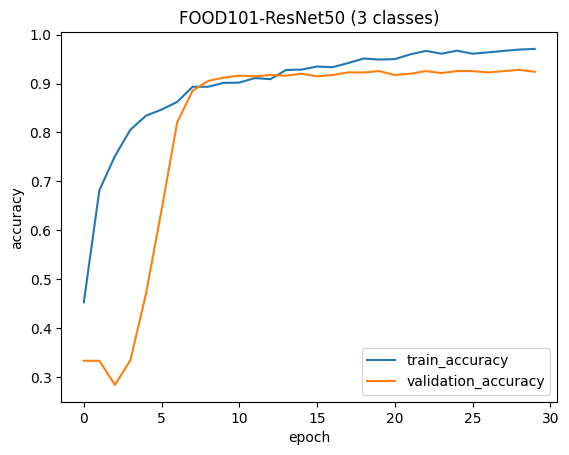

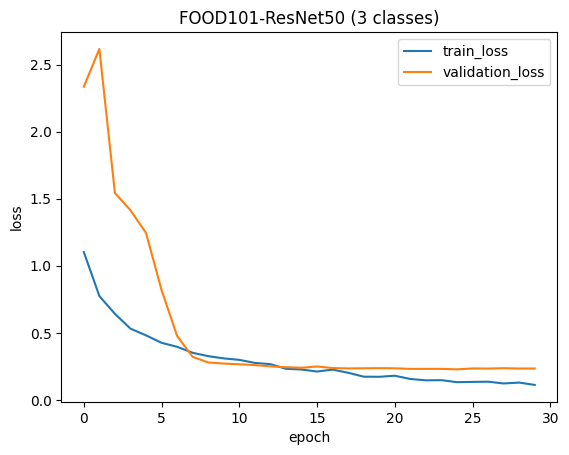

In [19]:
plot_accuracy(history, 'FOOD101-ResNet50 (3 classes)')
plot_loss(history, 'FOOD101-ResNet50 (3 classes)')

### **Predicting classes for new images using the best trained model**

In [20]:
%%time
# Loading the best saved model to make predictions
K.clear_session()
model_best = load_model(f'{WORK}/best_model_3class.keras', compile=False)

CPU times: user 2.01 s, sys: 186 ms, total: 2.2 s
Wall time: 2.17 s


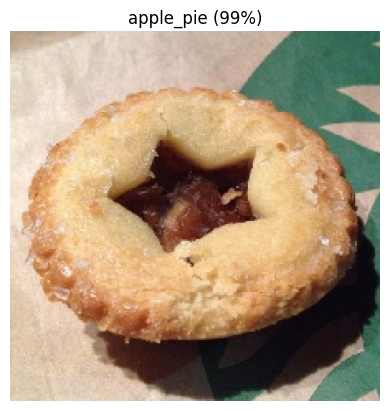

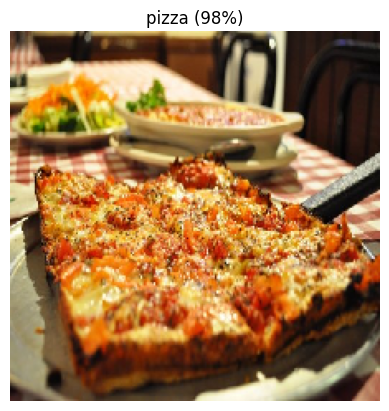

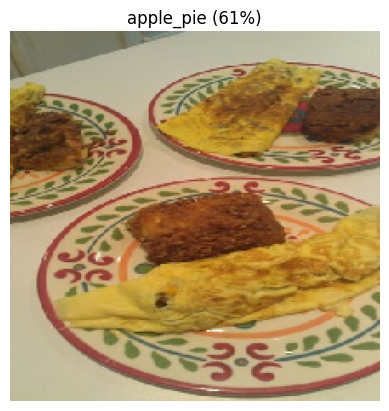

In [21]:
# Test on random images from the held-out test set
predict_class(model_best, sample_test_images(food_list), class_names_3)

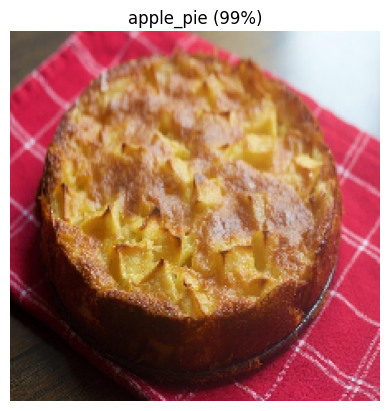

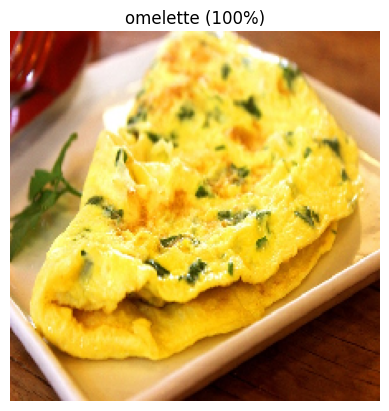

In [22]:
# Optional: test on images from the internet (needs Settings -> Internet ON)
!wget -q -O applepie.jpg https://cdn.pixabay.com/photo/2015/12/01/08/13/apple-pie-1071747_640.jpg
!wget -q -O omelette.jpg https://cdn.pixabay.com/photo/2015/05/20/16/11/kitchen-775746_640.jpg

web_images = [p for p in ['applepie.jpg', 'omelette.jpg'] if os.path.exists(p) and os.path.getsize(p) > 0]
if web_images:
    predict_class(model_best, web_images, class_names_3)
else:
    print("No web images downloaded (internet is probably off). Skipping.")

### **Fine tune ResNet50 model with 11 classes of data**

In [23]:
# Helper function to select n random food classes
def pick_n_random_classes(n):
    return sorted(random.sample(foods_sorted, n))

In [24]:
# Fixed list of 11 classes (swap in pick_n_random_classes(11) for a random set)
food_list = ['apple_pie', 'beef_carpaccio', 'bibimbap', 'cup_cakes', 'foie_gras', 'french_fries',
             'garlic_bread', 'pizza', 'spring_rolls', 'spaghetti_carbonara', 'strawberry_shortcake']
n = len(food_list)
missing = [f for f in food_list if f not in foods_sorted]
assert not missing, f"Unknown classes: {missing}"
print("Training on these food classes:\n", food_list)

Training on these food classes:
 ['apple_pie', 'beef_carpaccio', 'bibimbap', 'cup_cakes', 'foie_gras', 'french_fries', 'garlic_bread', 'pizza', 'spring_rolls', 'spaghetti_carbonara', 'strawberry_shortcake']


In [25]:
# Create the new data subset of n classes
print("Creating training data folder with new classes...")
dataset_mini(food_list, src_train, dest_train)
print("Creating test data folder with new classes...")
dataset_mini(food_list, src_test, dest_test)
print("train_mini: %d classes, %d images" % count_images(dest_train))
print("test_mini : %d classes, %d images" % count_images(dest_test))

Creating training data folder with new classes...
Linking images into apple_pie
Linking images into beef_carpaccio
Linking images into bibimbap
Linking images into cup_cakes
Linking images into foie_gras
Linking images into french_fries
Linking images into garlic_bread
Linking images into pizza
Linking images into spring_rolls
Linking images into spaghetti_carbonara
Linking images into strawberry_shortcake
Creating test data folder with new classes...
Linking images into apple_pie
Linking images into beef_carpaccio
Linking images into bibimbap
Linking images into cup_cakes
Linking images into foie_gras
Linking images into french_fries
Linking images into garlic_bread
Linking images into pizza
Linking images into spring_rolls
Linking images into spaghetti_carbonara
Linking images into strawberry_shortcake
train_mini: 11 classes, 8250 images
test_mini : 11 classes, 2750 images


In [26]:
K.clear_session()

train_generator, validation_generator = make_generators(dest_train, dest_test)
model = build_model(train_generator.num_classes)

checkpointer = ModelCheckpoint(filepath=f'{WORK}/best_model_11class.keras', verbose=1, save_best_only=True)
csv_logger = CSVLogger(f'{WORK}/history_11class.log')

history_11class = model.fit(train_generator,
                            validation_data=validation_generator,
                            epochs=EPOCHS,
                            verbose=1,
                            callbacks=[csv_logger, checkpointer])

model.save(f'{WORK}/model_trained_11class.keras')

Found 8250 images belonging to 11 classes.
Found 2750 images belonging to 11 classes.
Epoch 1/30
516/516 ━━━━━━━━━━━━━━━━━━━━ 0s 277ms/step - accuracy: 0.2485 - loss: 2.2780
Epoch 1: val_loss improved from None to 2.58246, saving model to /kaggle/working/best_model_11class.keras

Epoch 1: finished saving model to /kaggle/working/best_model_11class.keras
516/516 ━━━━━━━━━━━━━━━━━━━━ 195s 318ms/step - accuracy: 0.3952 - loss: 1.9204 - val_accuracy: 0.1636 - val_loss: 2.5825
Epoch 2/30
516/516 ━━━━━━━━━━━━━━━━━━━━ 0s 217ms/step - accuracy: 0.6441 - loss: 1.2292
Epoch 2: val_loss improved from 2.58246 to 0.71405, saving model to /kaggle/working/best_model_11class.keras

Epoch 2: finished saving model to /kaggle/working/best_model_11class.keras
516/516 ━━━━━━━━━━━━━━━━━━━━ 121s 235ms/step - accuracy: 0.6778 - loss: 1.1211 - val_accuracy: 0.8065 - val_loss: 0.7141
Epoch 3/30
516/516 ━━━━━━━━━━━━━━━━━━━━ 0s 211ms/step - accuracy: 0.7543 - loss: 0.8792
Epoch 3: val_loss improved from 0.71405 t

In [27]:
class_map_11 = train_generator.class_indices
class_names_11 = [name for name, idx in sorted(class_map_11.items(), key=lambda kv: kv[1])]
class_map_11

{'apple_pie': 0,
 'beef_carpaccio': 1,
 'bibimbap': 2,
 'cup_cakes': 3,
 'foie_gras': 4,
 'french_fries': 5,
 'garlic_bread': 6,
 'pizza': 7,
 'spaghetti_carbonara': 8,
 'spring_rolls': 9,
 'strawberry_shortcake': 10}

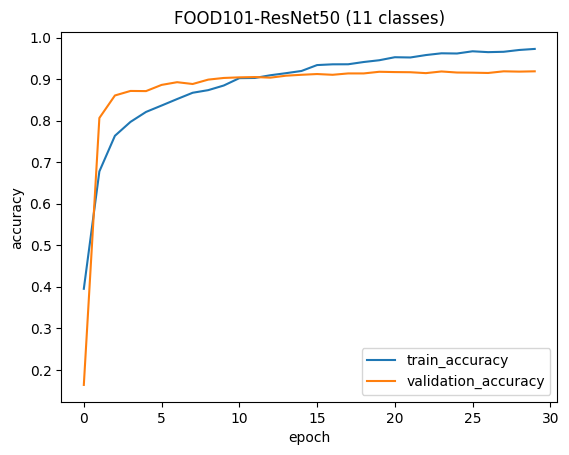

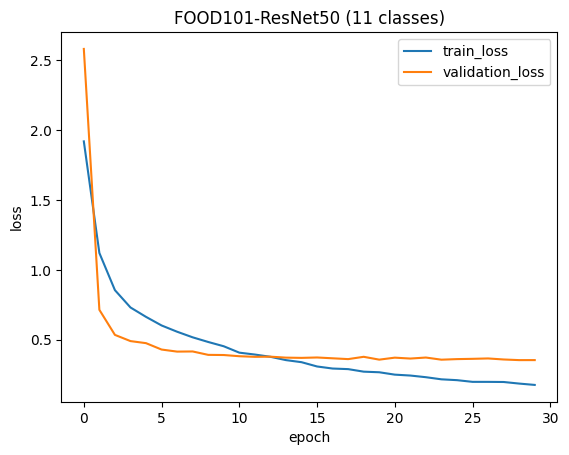

In [28]:
plot_accuracy(history_11class, 'FOOD101-ResNet50 (11 classes)')
plot_loss(history_11class, 'FOOD101-ResNet50 (11 classes)')

In [29]:
%%time
# Loading the best saved model to make predictions
K.clear_session()
model_best = load_model(f'{WORK}/best_model_11class.keras', compile=False)

CPU times: user 2.16 s, sys: 175 ms, total: 2.33 s
Wall time: 2.28 s


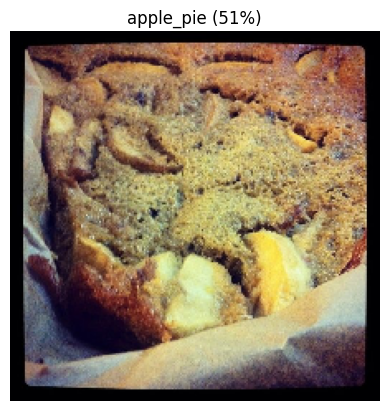

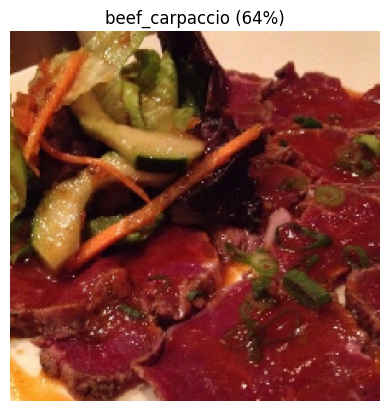

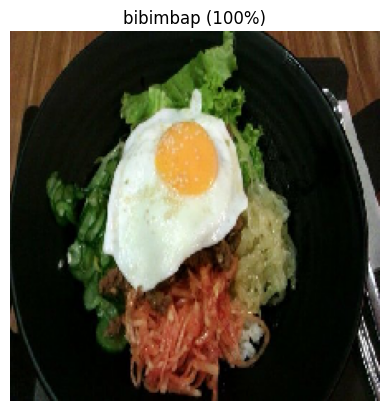

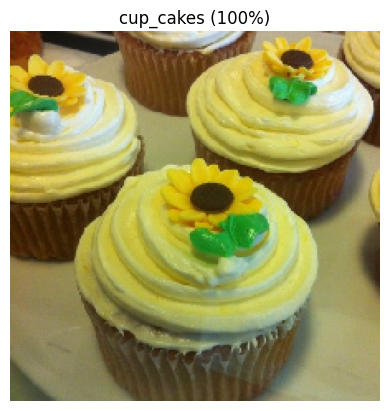

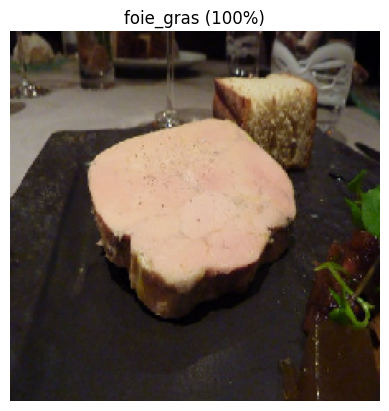

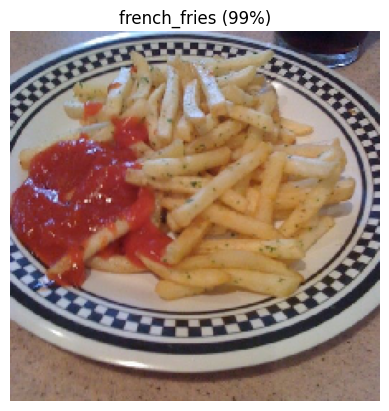

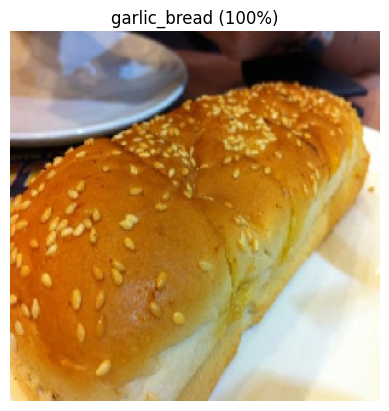

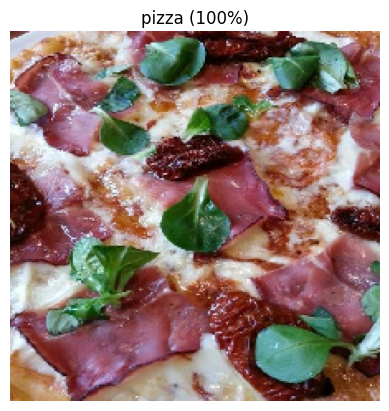

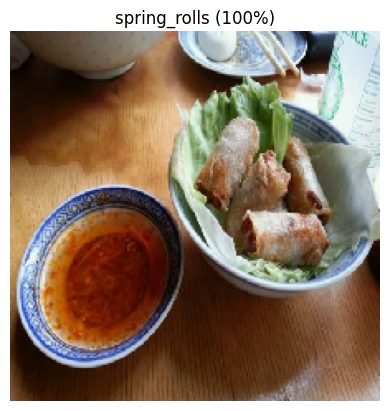

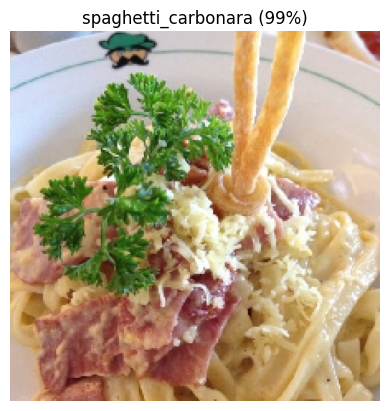

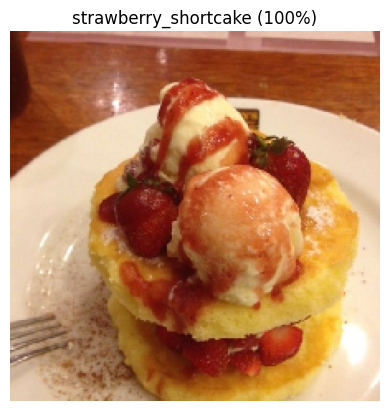

In [30]:
# Test on random images from the held-out test set
predict_class(model_best, sample_test_images(food_list), class_names_11)

In [31]:
# Overall accuracy of the best model on the 11-class test split
_, val_gen = make_generators(dest_train, dest_test)
model_best.compile(loss='categorical_crossentropy', metrics=['accuracy'])
loss, acc = model_best.evaluate(val_gen, verbose=1)
print(f"Test accuracy: {acc:.2%}")

Found 8250 images belonging to 11 classes.
Found 2750 images belonging to 11 classes.
172/172 ━━━━━━━━━━━━━━━━━━━━ 16s 61ms/step - accuracy: 0.9182 - loss: 0.3538
Test accuracy: 91.82%


In [32]:
# Optional: plot the model architecture (needs pydot + graphviz)
try:
    tf.keras.utils.plot_model(model_best, to_file=f'{WORK}/model_plot.png', show_shapes=True, show_layer_names=True)
    print("Saved model_plot.png")
except Exception as e:
    print("plot_model skipped:", e)

"dot" with args ['-Tpng', '/tmp/tmpnri4s3wk/tmpc0z535g2'] returned code: -6

stdout, stderr:
 b''
b"failed at node 10506[1]\ndot: maze.c:313: chkSgraph: Assertion `np->cells[1]' failed.\n"

plot_model skipped: "dot" with args ['-Tpng', '/tmp/tmpnri4s3wk/tmpc0z535g2'] returned code: -6


* **The model did well even when the number of classes are increased to 11**
* **Model training on all 101 classes takes some time**
* **It was taking more than an hour for one epoch when the full dataset is used for fine tuning**

---
## **Download the trained model**
The next cell packages the best 11-class model with its class labels into `food_model.zip` and shows download links.
You can also find every file under **Output** (right sidebar → `/kaggle/working`), or after **Save Version → Save & Run All** on the notebook's *Output* tab.

In [33]:
import os, json, shutil
from IPython.display import FileLink, display

WORK = "/kaggle/working"
MODEL_PATH = f"{WORK}/best_model_11class.keras"
print("Model found:", os.path.exists(MODEL_PATH))

EXPORT_DIR = f"{WORK}/food_model"
os.makedirs(EXPORT_DIR, exist_ok=True)

shutil.copy(MODEL_PATH, f"{EXPORT_DIR}/food_model.keras")

class_names_11 = sorted(['apple_pie', 'beef_carpaccio', 'bibimbap', 'cup_cakes', 'foie_gras',
                         'french_fries', 'garlic_bread', 'pizza', 'spring_rolls',
                         'spaghetti_carbonara', 'strawberry_shortcake'])
with open(f"{EXPORT_DIR}/labels.json", "w") as f:
    json.dump({"class_names": class_names_11, "img_size": [224, 224], "rescale": 1/255}, f, indent=2)

os.chdir(WORK)
shutil.make_archive("food_model", "zip", EXPORT_DIR)
print(f"food_model.zip: {os.path.getsize('food_model.zip')/1e6:.1f} MB")
display(FileLink("food_model.zip"))

Model found: True
food_model.zip: 177.2 MB


/kaggle/working/food_model.zip

## **Use the downloaded model**
Unzip `food_model.zip` on your computer, then run this anywhere with TensorFlow installed (`pip install tensorflow`).
It's run here too, as a check that the exported files work on their own.

In [34]:
import json
import numpy as np
import tensorflow as tf

MODEL_DIR = "/kaggle/working/food_model"   # on your computer: the folder you unzipped

food_model = tf.keras.models.load_model(f"{MODEL_DIR}/food_model.keras", compile=False)
with open(f"{MODEL_DIR}/labels.json") as f:
    meta = json.load(f)
labels, size = meta["class_names"], tuple(meta["img_size"])

def predict_food(image_path, top_k=3):
    img = tf.keras.utils.load_img(image_path, target_size=size)
    x = tf.keras.utils.img_to_array(img)[None] * meta["rescale"]
    probs = food_model.predict(x, verbose=0)[0]
    best = np.argsort(probs)[::-1][:top_k]
    return [(labels[i], float(probs[i])) for i in best]

# Example: try it on one test image
example = sample_test_images(food_list)[0] if "sample_test_images" in globals() else "your_photo.jpg"
print(example)
for name, p in predict_food(example):
    print(f"  {name:22s} {p:.1%}")

/kaggle/working/test/apple_pie/2517059.jpg
  apple_pie              99.9%
  garlic_bread           0.0%
  foie_gras              0.0%
